# Notebook 2: CFD Baseline

The purpose of this notebook is to build the physics based CFD baseline. It removes the time-walk with a simple formula, measures the timing resolution σ_t and comapres with previous results.

There are two levels of correction.
1. Global 1/A correction; fit $Δt= a/{pulse integral} +b $ once for all angles and subtract it.
2. Per angle correction; the same fit is done for each angle separately.

Notes;
`pulse_integral` is used instead of pulse height as previously.
The file `convert_to_hdf5.py` is used which keeps only the pixel with the most charge so only one hit per event. In this way charge sharing does not disturb the fit.

In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import pickle
import os

os.makedirs('plots', exist_ok=True)
os.makedirs('data/derived', exist_ok=True)

In [2]:
#Load the columns needed from the HDF5 file made by convert_to_hdf5.py
with h5py.File('../data/hits.h5', 'r') as f:
    t_raw          = np.array(f['t_raw'])
    t_true         = np.array(f['t_true'])
    pulse_integral = np.array(f['pulse_integral'])
    cluster_charge = np.array(f['cluster_charge'])
    cluster_size   = np.array(f['cluster_size'])
    col_frac       = np.array(f['col_frac'])
    row_frac       = np.array(f['row_frac'])
    angle_deg      = np.array(f['angle_deg'])
    v_bias         = np.array(f['v_bias'])
    pixel_charge   = np.array(f['pixel_charge'])

#Remove the charge-only rows where the t_raw and pulse_integral are NaN
valid = ~np.isnan(t_raw) & ~np.isnan(pulse_integral)
orig_idx = np.nonzero(valid)[0]  #Row numbers of the kept rows in hits.h5 are saved so later notebooks can match the corrected values back to the original rows

t_raw          = t_raw[valid]
t_true         = t_true[valid]
pulse_integral = pulse_integral[valid]
cluster_charge = cluster_charge[valid]
cluster_size   = cluster_size[valid]
col_frac       = col_frac[valid]
row_frac       = row_frac[valid]
angle_deg      = angle_deg[valid]
v_bias         = v_bias[valid]
pixel_charge   = pixel_charge[valid]

delta_t = t_raw - t_true  # ps
print(f'Valid digitized hits: {valid.sum()} / {len(valid)}')

Valid digitized hits: 85899 / 85985


## Resolution metric

σ_t is the width of a Gaussian fit to the Δt values within ±200 ps of their median. The fit ignores the far tails, so σ_t describes the core of the distribution, not the late charge-sharing events.

In [3]:
def fit_resolution(residuals, clip_ps=200):
    """Returns (mu,sigma) in ps from a Gaussian fit to the residuals. Only values within +- clip_ps of the median are used
    so that the long tails don't inflate sigma. The clip is around the median instead of zero because the residuals have a
    constant offset of about 150 ps."""
    center = np.median(residuals)
    clipped = residuals[np.abs(residuals - center) < clip_ps]
    mu, sigma = norm.fit(clipped)
    return mu, sigma

#Resolution with no correction
mu_raw, sigma_raw = fit_resolution(delta_t)
print(f'Raw (no correction): sigma = {sigma_raw:.1f} ps  (mu = {mu_raw:.1f} ps)')

Raw (no correction): sigma = 61.8 ps  (mu = 285.0 ps)


## Level 1; Global `1/pulse_integral` correction

In [4]:
inv_pi = 1.0 / pulse_integral

#Fit only on the central population. This is to prevent a few late points with large 1/pulse_integral to distort the fit
fit_mask = np.abs(delta_t - np.median(delta_t)) < 200

#Straight line fit
coeffs = np.polyfit(inv_pi[fit_mask], delta_t[fit_mask], deg=1)

#Subtract the fitted curve from all rows
delta_t_cfd1 = delta_t - np.polyval(coeffs, inv_pi)

mu1, sigma1 = fit_resolution(delta_t_cfd1)
print(f'coeffs (a, b) = {coeffs}')
print(f'After global 1/pulse_integral correction: sigma = {sigma1:.1f} ps  '
      f'(mu = {mu1:.1f} ps)')
print(f'Improvement over raw: {100 * (sigma_raw - sigma1) / sigma_raw:.1f}%')

coeffs (a, b) = [1.29897543e-03 1.76343718e+02]
After global 1/pulse_integral correction: sigma = 55.2 ps  (mu = 0.4 ps)
Improvement over raw: 10.6%


## Level 2; Per-angle correction


In [5]:
angles = sorted(np.unique(angle_deg))

delta_t_cfd2 = delta_t.copy()
per_angle_coeffs = {}

for a in angles:
    mask = angle_deg == a
    #Same central population cut as before but centered on each angle's median
    fit_mask_a = mask & (np.abs(delta_t - np.median(delta_t[mask])) < 200)
    c = np.polyfit(inv_pi[fit_mask_a], delta_t[fit_mask_a], deg=1)
    per_angle_coeffs[a] = c
    delta_t_cfd2[mask] -= np.polyval(c, inv_pi[mask])

mu2, sigma2 = fit_resolution(delta_t_cfd2)
print(f'After per-angle CFD: sigma = {sigma2:.1f} ps  (mu = {mu2:.1f} ps)')
print(f'Improvement over raw: {100 * (sigma_raw - sigma2) / sigma_raw:.1f}%')
print(f'Improvement over global 1/PI: {100 * (sigma1 - sigma2) / sigma1:.1f}%')

for a in angles:
    d = delta_t_cfd2[angle_deg == a]
    _, s = fit_resolution(d)
    print(f'  angle={int(a):>2}deg  n={int((angle_deg==a).sum()):>6}  sigma={s:6.1f} ps')

After per-angle CFD: sigma = 55.0 ps  (mu = 0.4 ps)
Improvement over raw: 11.0%
Improvement over global 1/PI: 0.4%
  angle= 0deg  n= 17000  sigma=  50.2 ps
  angle= 5deg  n= 14278  sigma=  52.4 ps
  angle=10deg  n= 14162  sigma=  54.9 ps
  angle=15deg  n= 13891  sigma=  56.1 ps
  angle=20deg  n= 13503  sigma=  58.0 ps
  angle=25deg  n= 13065  sigma=  59.8 ps


## Comparison plot; raw vs global vs per-angle

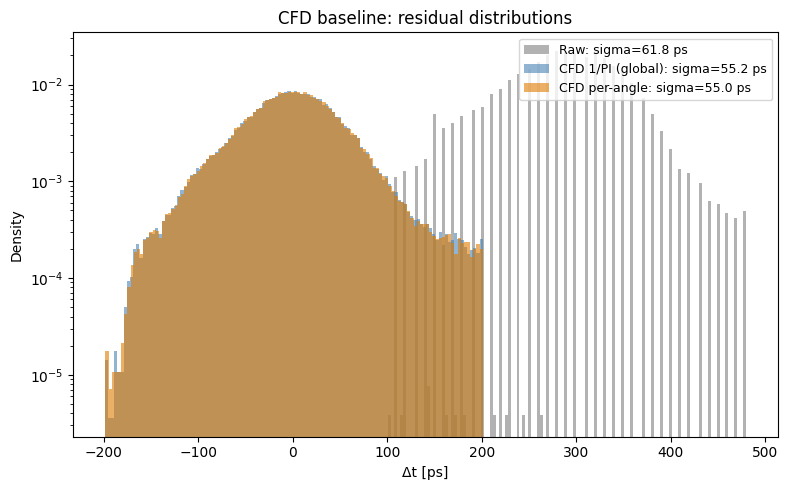

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))

methods = {
    'Raw':               (delta_t,      sigma_raw),
    'CFD 1/PI (global)': (delta_t_cfd1, sigma1),
    'CFD per-angle':     (delta_t_cfd2, sigma2),
}
colors = ['grey', 'steelblue', '#E07B00']

for (label, (res, sigma)), color in zip(methods.items(), colors):
    #Same window that the resoultion fit uses
    center = np.median(res)
    clipped = res[np.abs(res - center) < 200]
    ax.hist(clipped, bins=120, density=True, alpha=0.6, color=color,
            label=f'{label}: sigma={sigma:.1f} ps')

#Log y axis is used so that the tails are visible next to the peak
ax.set_yscale('log')
ax.set_xlabel('Δt [ps]')
ax.set_ylabel('Density')
ax.set_title('CFD baseline: residual distributions')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('plots/05_cfd_baseline_comparison.pdf', dpi=150)
plt.show()

The two corrected distributions which are represented in blue and orange are almost on top of each other. They are centred at close to 0 ps with σ = 55.2 and 55.0 ps respectively. The raw distribution represented in gray is centred at 285 ps with a σ = 61.8 ps. The grey histogram has gaps between bars due to Δt being quantized in 10 ps steps. The corrected data are smooth as subtracting a continuous 1/pulse_integral term moves each value by a different amount. Both distributions have tails on the right side of the peak due to late events. The corrections reduce this but it is not removed. From this plot it can be seen that the per-angle correction does not improve much further than the global correction. 

## Resolution vs angle; raw vs CFD

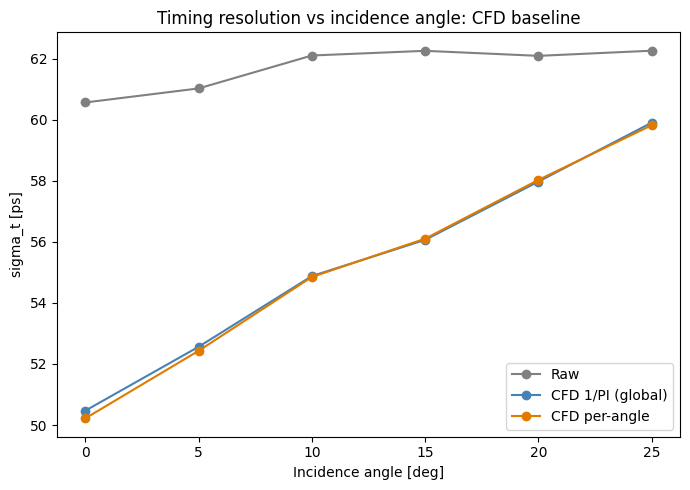

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))

sigma_raw_by_angle  = [fit_resolution(delta_t[angle_deg == a])[1]      for a in angles]
sigma_cfd1_by_angle = [fit_resolution(delta_t_cfd1[angle_deg == a])[1] for a in angles]
sigma_cfd2_by_angle = [fit_resolution(delta_t_cfd2[angle_deg == a])[1] for a in angles]

ax.plot(angles, sigma_raw_by_angle,  'o-', color='grey',      label='Raw')
ax.plot(angles, sigma_cfd1_by_angle, 'o-', color='steelblue', label='CFD 1/PI (global)')
ax.plot(angles, sigma_cfd2_by_angle, 'o-', color='#E07B00',   label='CFD per-angle')

ax.set_xlabel('Incidence angle [deg]')
ax.set_ylabel('sigma_t [ps]')
ax.set_title('Timing resolution vs incidence angle: CFD baseline')
ax.legend()
plt.tight_layout()
plt.savefig('plots/06_sigma_vs_angle_cfd.pdf', dpi=150)
plt.show()

From this plot it can be seen that for raw data σ_t is about 60.5 ps at 0° and rises only slightly to about 62 ps at 25°. For the corrected cases σ_t is about 50 ps at 0° and rises to about 60 ps at 25°. This shows that the correction is more effective at smaller angles and the gap with raw results decreases with increasing incidence angle. This is because the time-walk term is removed at every angle but the spread increases due to charge sharing. The amplitude only formula used for the fit does not account for this.

## Save corrected arrays and coefficients

In [8]:
#Corrected residuals for the next notebooks. orig_idx links each value to its row in hits.h5
with h5py.File('data/derived/cfd_baseline.h5', 'w') as f:
    f.create_dataset('orig_idx', data=orig_idx)
    f.create_dataset('delta_t', data=delta_t)
    f.create_dataset('delta_t_cfd1', data=delta_t_cfd1)
    f.create_dataset('delta_t_cfd2', data=delta_t_cfd2)

#Fitted a and b values so that the correction can be applied to new data later
os.makedirs('models', exist_ok=True)
with open('models/cfd_coeffs.pkl', 'wb') as f:
    pickle.dump({'global_coeffs': coeffs, 'per_angle_coeffs': per_angle_coeffs}, f)

#Summary table
print(f'{"Method":<22}{"sigma_t [ps]":>14}')
print(f'{"Raw":<22}{sigma_raw:>14.1f}')
print(f'{"CFD 1/PI (global)":<22}{sigma1:>14.1f}')
print(f'{"CFD per-angle":<22}{sigma2:>14.1f}')

Method                  sigma_t [ps]
Raw                             61.8
CFD 1/PI (global)               55.2
CFD per-angle                   55.0
